# J++'s gradient rules, written once, on five architectures

<a href="https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jpp-kola/examples/methods/jpp_rules_colab.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**The J++ lens's LRP rules are a few `tl.when(selector, edit)` lines that pick operations by name and module, and the same list runs on five small language models: four transformers and a state-space model.**

The J++ lens (Kola Ayonrinde and Jack Lindsey, [LessWrong, October 2026](https://www.lesswrong.com/posts/nc9dHfcB22JdMzGbr/j-lens-jacobian-filtering-enables-more-faithful-workspace); [code](https://github.com/safety-research/jpp_lens)) computes its Jacobians through a Layer-wise Relevance Propagation (LRP) backward pass: a short list of rules that leave every forward value unchanged and change only gradients. They hold a normalization's scale constant (the LN rule), hold an activation's gate constant (the identity rule) and halve the gradient through the gated-MLP product (the half rule). This notebook writes those rules once, runs them on each model, checks that they landed, and draws the edited operations. It needs no GPU and no Hugging Face token; the stored run took 3.2 minutes end to end on two CPU cores of a Linux machine, model downloads included (free Colab was not timed).

This is the short version. The [full notebook](https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jpp-kola/examples/methods/jpp_lens_architectures_colab.ipynb) goes on to fit the J-lens, the R-lens and the J++ lens with these rules and score them; its result table is copied at the end.

In [1]:
# Colab has torch and transformers; this adds TorchLens and, if missing, Graphviz for the drawing.
%pip install -q "torchlens>=3.0.3" "transformers>=4.56"
!which dot > /dev/null || apt-get -qq install -y graphviz > /dev/null

Note: you may need to restart the kernel to use updated packages.


## Five models

Each loads in float32 from the Hugging Face Hub and is released before the next one loads (about 2.8 GB of downloads in all). Next to each repository is the list of functions the rules should edit in that model; the check below holds the rules to it. Gemma-3-270m comes from `unsloth/gemma-3-270m`, an ungated copy of `google/gemma-3-270m`, so no token is needed; the weights remain under the Gemma terms of use.

In [2]:
import collections
import functools
import gc
import operator
import shutil
import time
import warnings

import pandas as pd
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

import torchlens as tl

transformers.logging.set_verbosity_error()  # Mamba without its CUDA kernels says so at length
transformers.logging.disable_progress_bar()
warnings.filterwarnings("ignore", message=".*fast path.*")
warnings.filterwarnings("ignore", message="TorchLens captured a vmap transform")  # transformers 4
tl.errors.quiet("capture_memory_threshold_exceeded")  # torchlens 3.0.3 warns on view traces

assert shutil.which("dot"), "Graphviz is missing: install it (apt-get install graphviz) and rerun"
MODELS = {  # name: (Hub repository, the functions the rules should edit in it)
    "Qwen2.5-0.5B": ("Qwen/Qwen2.5-0.5B", "rsqrt silu mul"),  # RMSNorm, SiLU-gated MLP
    "SmolLM2-135M": ("HuggingFaceTB/SmolLM2-135M", "rsqrt silu mul"),  # Llama family, same ops
    "Gemma-3-270m": ("unsloth/gemma-3-270m", "rsqrt gelu mul"),  # RMSNorm, GELU-gated MLP
    "Mamba-130m": ("state-spaces/mamba-130m-hf", "rsqrt"),  # state-space model: RMSNorm, no MLP
    "GPT-2 small": ("openai-community/gpt2", "layer_norm tanh"),  # LayerNorm, ungated tanh-GELU MLP
}
PROMPT, t_start = "The Eiffel Tower is in the city of", time.time()
print(*(f"{lib.__name__} {lib.__version__}" for lib in (torch, transformers, tl)), sep=", ")

torch 2.15.0+cpu, transformers 5.22.2, torchlens 3.0.3


## The rules, written once

Each edit below returns the same value as the operation it replaces (up to float32 round-off), with a different autograd graph. `lrp_rules` pairs each edit with a selector that says which operations it applies to: `tl.func("rsqrt")` is every `rsqrt` call, `& mlp` keeps the ones inside an MLP module, `- attention` drops the ones inside attention. The first three entries are the post's rules (its Table 5); the next three cover operations Qwen never calls, each following the released code or the paper the post builds on.

In [3]:
def hold_constant(out, *, ctx):
    """The value, with no gradient through it (RMSNorm's rsqrt; the tanh inside GPT-2's GELU)."""
    return out.detach()


def silu_identity(out, *, ctx):
    """silu(z) = z * sigmoid(z), with the sigmoid held constant."""
    z = ctx.args[0]
    return z * torch.sigmoid(z).detach()


def half(out, *, ctx):
    """Half of the gradient through the gated-MLP product."""
    return 0.5 * out + 0.5 * out.detach()


def gelu_identity(out, *, ctx):
    """gelu(z) = z * Phi(z), with the gate Phi (or its tanh approximation) held constant."""
    z = ctx.args[0]
    if ctx.kwargs.get("approximate", "none") == "tanh":
        gate = 0.5 * (1 + torch.tanh((2 / torch.pi) ** 0.5 * (z + 0.044715 * z**3)))
    else:
        gate = 0.5 * (1 + torch.erf(z / 2**0.5))
    return z * gate.detach()


def layernorm_identity(out, *, ctx):
    """LayerNorm with 1 / std(x) held constant."""
    x, _, weight, bias, eps = ctx.args[:5]
    scale = torch.rsqrt(x.var(-1, keepdim=True, unbiased=False) + eps).detach()
    return (x - x.mean(-1, keepdim=True)) * scale * weight + bias


def modules_of(model, kind, gated=False):
    """One selector for every module whose class name ends with `kind`; None if there is none."""
    fits = (m for m in model.named_modules() if type(m[1]).__name__.endswith(kind))
    names = [name for name, mod in fits if not gated or hasattr(mod, "up_proj")]
    return functools.reduce(operator.or_, map(tl.in_module, names)) if names else None


def lrp_rules(model):
    """The J++ LRP rules for one model: {rule: (selector, edit)}; rules it has no modules for drop."""
    attention, mlp = modules_of(model, "Attention"), modules_of(model, "MLP")
    gated_mlp, rsqrt = modules_of(model, "MLP", gated=True), tl.func("rsqrt")
    rules = {
        # the post's three rules
        "LN rule (RMSNorm)": (rsqrt if attention is None else rsqrt - attention, hold_constant),
        "identity rule (SiLU)": (None if mlp is None else tl.func("silu") & mlp, silu_identity),
        "half rule (gated MLP)": (None if gated_mlp is None else tl.func("mul") & gated_mlp, half),
        # one line added for Gemma 3, then two for GPT-2
        "identity rule (GELU)": (None if mlp is None else tl.func("gelu") & mlp, gelu_identity),
        "LN rule (LayerNorm)": (tl.func("layer_norm"), layernorm_identity),
        "identity rule (tanh GELU)": (
            None if mlp is None else tl.func("tanh") & mlp,
            hold_constant,
        ),
    }
    return {rule: (sel, edit) for rule, (sel, edit) in rules.items() if sel is not None}


def lrp_trace(model, ids, rules, **capture):
    """One traced forward pass under the rules (none: a plain trace); `&` merges the clauses."""
    options = tl.options.CaptureOptions(**capture) if capture else None
    if not rules:
        return tl.trace(model, ids, capture=options)
    recipe = functools.reduce(operator.and_, (tl.when(sel, edit) for sel, edit in rules.values()))
    return tl.trace(model, ids, capture=options, intervene=recipe, on_zero_fire="disclose")

## The same rules on five models

Each model runs one prompt untraced, traced under the rules, and through live `save_mode="view"` traces with and without the rules. The cell asserts three things per model: the logits under the rules match the untraced model's within float32 round-off, the rules together change the gradient of the top next-token logit with respect to an early block's output, and the trace's own record of edited operations (`op.is_edited`, `op.modules`) shows one edited operation of each expected function in every module where its rule belongs, and none anywhere else.

In [4]:
EDITS = {  # function: (the rule that edits it, the kind of module that should hold one such edit)
    "rsqrt": ("LN rule (RMSNorm)", "RMSNorm"),
    "silu": ("identity rule (SiLU)", "MLP"),
    "mul": ("half rule (gated MLP)", "MLP"),
    "gelu": ("identity rule (GELU)", "MLP"),
    "layer_norm": ("LN rule (LayerNorm)", "LayerNorm"),
    "tanh": ("identity rule (tanh GELU)", "MLP"),
}


def edit_sites(trace):
    """What the trace recorded: {function: [the modules around each operation a rule edited]}."""
    sites = collections.defaultdict(list)
    for op in trace.ops:
        if op.is_edited:
            sites[op.func_name.strip("_")].append({m.rsplit(":", 1)[0] for m in op.modules})
    return sites


def homes(model, kind):
    """The modules of one kind that sit outside attention (no MLP is ever inside it)."""
    kinds = {name: type(mod).__name__ for name, mod in model.named_modules()}
    attention = tuple(name + "." for name, k in kinds.items() if k.endswith("Attention"))
    return {
        name for name, k in kinds.items() if k.endswith(kind) and not name.startswith(attention)
    }


def gradient_at(model, ids, rules, source):
    """d(top next-token logit) / d(output of block `source`), through a live view-mode trace."""
    trace = lrp_trace(model, ids, rules, save_mode="view", save_budget=None)
    out = trace[source].out
    out = out[0] if isinstance(out, (tuple, list)) else out  # some blocks return a tuple
    return torch.autograd.grad(trace.output.logits[0, -1].max(), out)[0]


table = {}
for name, (repo, expected) in MODELS.items():
    extra = {} if "mamba" in repo else {"attn_implementation": "eager"}
    model = AutoModelForCausalLM.from_pretrained(repo, dtype=torch.float32, **extra).eval()
    model.config.use_cache = False
    ids = AutoTokenizer.from_pretrained(repo)(PROMPT, return_tensors="pt").input_ids
    n = model.config.num_hidden_layers  # the blocks are the ModuleList of that length
    stack = next(
        k for k, m in model.named_modules() if type(m).__name__ == "ModuleList" and len(m) == n
    )
    rules = lrp_rules(model)
    with torch.no_grad():
        reference = model(ids).logits  # the untraced model
        trace = lrp_trace(model, ids, rules)
    logit_change = float((reference - trace.output.logits).abs().max() / reference.abs().max())
    plain, lrp = (gradient_at(model, ids, r, f"{stack}.{n // 8}") for r in ({}, rules))
    grad_change = float((plain - lrp).norm() / plain.norm())
    assert logit_change < 1e-4, f"{name}: the rules changed the forward pass"
    assert grad_change > 1e-3, f"{name}: the rules left the gradient unchanged"
    sites = edit_sites(trace)
    assert set(sites) == set(expected.split()), f"{name}: the rules edited {sorted(sites)}"
    for function, around in sites.items():  # one edit in each module of the rule's kind, no other
        want = homes(model, EDITS[function][1])
        placed = sorted(sorted(modules & want) for modules in around)
        assert placed == [[module] for module in sorted(want)], f"{name}: misplaced {function} edit"
    table[name] = {rule: str(len(sites.get(f, "")) or "") for f, (rule, _) in EDITS.items()} | {
        "norm modules outside attention": len(homes(model, "RMSNorm") | homes(model, "LayerNorm")),
        "MLP modules": len(homes(model, "MLP")),
        "largest logit change, relative": f"{logit_change:.0e}",
        "gradient change at an early block, relative": f"{grad_change:.2f}",
    }
    if name == "SmolLM2-135M":
        drawn, drawn_block = trace, f"{stack}.0"  # the one trace kept, for the drawing below
    del model, trace, reference, plain, lrp
    gc.collect()  # the next model loads into freed memory

pd.DataFrame(table)  # a blank cell: the rule edited nothing in that model, as expected

,Qwen2.5-0.5B,SmolLM2-135M,Gemma-3-270m,Mamba-130m,GPT-2 small
LN rule (RMSNorm),49,61,73,25,
identity rule (SiLU),24,30,,,
half rule (gated MLP),24,30,18,,
identity rule (GELU),,,18,,
LN rule (LayerNorm),,,,,25
identity rule (tanh GELU),,,,,12
norm modules outside attention,49,61,73,25,25
MLP modules,24,30,18,0,12
"largest logit change, relative",2e-06,1e-06,5e-07,0e+00,5e-07
"gradient change at an early block, relative",0.89,0.89,0.87,1.19,1.80


Qwen2.5 and SmolLM2 take the post's three rules as written. Gemma 3 calls GELU where Qwen calls SiLU, and its query and key norms sit inside attention, so they keep the plain gradient. Mamba has no MLP: only the RMSNorm rule applies, and its selective scan keeps the plain gradient, since the post gives no rule for it. GPT-2 matches the LayerNorm and tanh-GELU entries, and the half rule finds nothing because its MLP is not gated.

These checks cover placement and the combined effect. The [full notebook](https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jpp-kola/examples/methods/jpp_lens_architectures_colab.ipynb) also checks each edit on its own, in float64, for the value and the derivative its rule prescribes. A new architecture needs the same checks: its module names, fused operations or extra products can make a selector miss an operation or match the wrong one.

## The edited operations, drawn

`trace.draw` marks every operation an intervention edited. This is the first MLP of SmolLM2-135M, from the one trace the loop kept: the identity rule on `silu` and the half rule on the gate product, outlined in purple. The header counts the edits in the whole trace, the 61 `rsqrt` edits of the LN rule included (draw `module=f"{drawn_block}.post_attention_layernorm"` to see one).

wall time: 3.1 min on 2 CPU threads


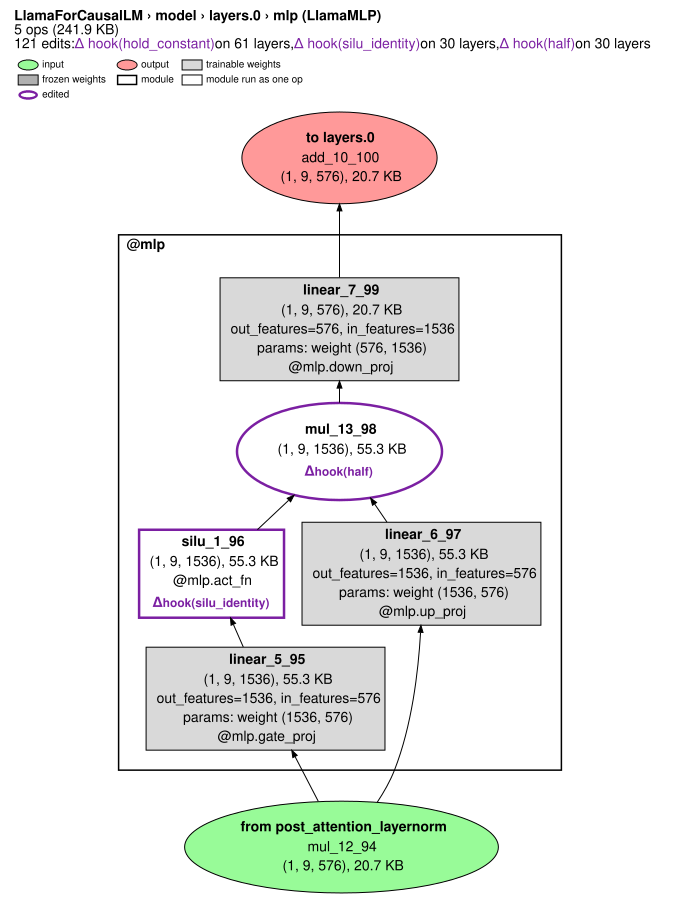

In [5]:
drawing = drawn.draw("jpp_rules_mlp", file_format="svg", module=f"{drawn_block}.mlp")
print(f"wall time: {(time.time() - t_start) / 60:.1f} min on {torch.get_num_threads()} CPU threads")
drawing

## Results from the full notebook

The [full notebook](https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jpp-kola/examples/methods/jpp_lens_architectures_colab.ipynb) fits three lenses with these traces and scores them on the post's readout tasks next to the logit lens: the J-lens (plain backward pass), the R-lens (the same Jacobian under the rules above) and the J++ lens (per-cluster Jacobians under the rules, combined with learned weights). The table is copied from its stored run (torch 2.5.1, transformers 4.57.6), not computed here: recall@10 (%) on held-out items, a hit at any of seven readout layers, macro-averaged over the tasks with scored items for that model, with 95% bootstrap intervals in brackets. The last column is a paired difference in percentage points. Each model is scored on its own items, so the rows do not rank the models.

| Model | Logit lens | J-lens | R-lens | J++ lens | J++ minus R-lens |
|---|---|---|---|---|---|
| Qwen2.5-0.5B | 12.6 [5, 20] | 37.2 [29, 45] | 36.0 [28, 44] | 37.0 [29, 45] | +1.0 [-5, +6] |
| SmolLM2-135M | 8.3 [0, 21] | 27.5 [16, 39] | 33.4 [21, 44] | 41.9 [31, 52] | +8.5 [+2, +17] |
| Gemma-3-270m | 17.7 [10, 26] | 23.0 [16, 31] | 24.7 [19, 32] | 33.9 [25, 43] | +9.2 [+2, +18] |
| GPT-2 small | 8.4 [5, 13] | 3.9 [1, 7] | 8.4 [5, 13] | 12.3 [8, 18] | +3.9 [-1, +8] |

Caveats: one seed, 8 fitting sequences per model (the post uses 64), 37 to 42 dev items and 152 to 178 test items over two to four tasks, 5 to 10 of each model's 56 expert Jacobians falling back to the pooled one, intervals that cover test-item resampling only, and Mamba not fitted; it is a demo of porting the method, not a replication.